# 40 - Confirming the `(alpha, z_A0_eff)` Identifiability Finding

Follow-up to `notebooks/39_wu2003_identifiability_and_sbc_repair.ipynb`, which found
`(alpha, z_A0_eff)` is a real, representation-robust coupling under S-B (FIM off-diagonal
`+0.39` to `+0.68`, survives raw trajectory) at one operating point
(`xi_reb=0.70, z_A0_eff=0.80`, others nominal), while the originally-suspected
`(xi_reb, z_A0_eff)` pairing is not confounded at all. Before committing training budget to
a pair-specific fix (correlated reparameterisation, targeted features, etc. -- see
`docs/Manuscript/system_ii_sbc_repair_directions.md`), this notebook does the two cheap
checks that should happen first:

1. **Visual confirmation** -- does an actual trained posterior show the predicted banana
   shape in `(alpha, z_A0_eff)` space, the same way `nb29b` visually confirmed
   `(alpha, beta_r)`'s correlation (`0.998`) in a real calibrated posterior, not just the
   deterministic FIM?
2. **Replication across operating points** -- nb39 checked exactly one point. Does the
   coupling persist across other draws from the lognormal prior, or was it specific to that
   one point?

**Caveat carried over from nb37/38/39:** the posteriors used for Part 1 below are the
`identity`-preprocessing posteriors trained on the matched 5k lognormal bank
(`sbi-logs/wu2003_posterior_lognormal_true_n5000_identity_seed{0,1,2}.pkl`) -- they are
**not calibrated** (nb38 found min-KS `p` as low as `4.5e-10` for this exact bank/variant).
Use them here only for a qualitative shape/correlation check, the same way `nb26`'s original,
also-uncalibrated single SNPE run was used to first notice `(alpha, beta_r)`-style structure
before the deterministic-scan machinery existed. Do not read a specific correlation number
from these posteriors as a calibrated estimate of anything.

This notebook does not train anything and does not modify any existing artifact -- it only
loads already-trained posteriors and runs the deterministic simulator. Written to be run
manually (not executed here).

In [1]:
import pathlib, pickle, json
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import torch
import jax.numpy as jnp

cwd = pathlib.Path.cwd().resolve()
ROOT = cwd if (cwd / 'src').exists() else cwd.parent
import sys
sys.path.insert(0, str(ROOT / 'src'))
sys.path.insert(0, str(ROOT / 'scripts'))

from cstr_sbi.recycle.physics import (
    PARAM_NAMES, NOMINAL_CTRL_SB, NOMINAL_INLET, NOMINAL_THETA,
    simulate_trajectory_explicit_jit, extract_observations_explicit,
)
from cstr_sbi.recycle.priors import PRIOR_LOW_5D, PRIOR_HIGH_5D
from cstr_sbi.recycle.simulator import nominal_warm_start
from cstr_sbi.recycle.summaries import compute_summaries, summary_names, RAW_INDEX, SB_CHANNELS
from sbi_pipeline import _structure_config, _simulate_summary
from fim_utils import compute_fim, offdiag_ratio, cov_offdiag_corr, crb_report

DATA = ROOT / 'data'
RESULTS = ROOT / 'results'
SBI_LOGS = ROOT / 'sbi-logs'
FIGURES = ROOT / 'figures'
for path in [DATA, RESULTS, SBI_LOGS, FIGURES]:
    path.mkdir(exist_ok=True)

STRUCTURE = 'S-B'
NOISE_PCT = 0.003
LOG_SIGMA = np.array([0.16, 0.16, 0.10, 0.16, 0.055], dtype=np.float32)
ALPHA_IDX, BETA_R_IDX, ETA_COL_IDX, XI_REB_IDX, Z_A0_IDX = range(5)

print(f'ROOT={ROOT}')
print(f'Parameters: {PARAM_NAMES}')


ROOT=/Users/simo/inso-po-RD/cstr-model-optimisation/research_project
Parameters: ['alpha', 'beta_r', 'eta_col', 'xi_reb', 'z_A0_eff']


In [2]:
class TruncatedLogNormalPrior(torch.distributions.Distribution):
    """Same class as nb37/38/39 -- must be defined under this exact name before
    unpickling any `wu2003_posterior_lognormal_*` posterior: `sbi`'s SNPE object stores a
    reference to the prior instance, and pickle resolves custom classes by
    module-qualified name at load time."""
    arg_constraints = {}
    has_rsample = False

    def __init__(self, median, sigma, low, high, validate_args=False):
        self.median = torch.as_tensor(median, dtype=torch.float32)
        self.sigma = torch.as_tensor(sigma, dtype=torch.float32)
        self.low = torch.as_tensor(low, dtype=torch.float32)
        self.high = torch.as_tensor(high, dtype=torch.float32)
        self.mu = torch.log(self.median)
        self.base = torch.distributions.Normal(self.mu, self.sigma)
        lo_z = (torch.log(self.low) - self.mu) / self.sigma
        hi_z = (torch.log(self.high) - self.mu) / self.sigma
        standard = torch.distributions.Normal(torch.zeros_like(self.mu), torch.ones_like(self.mu))
        self.log_norm = torch.log(standard.cdf(hi_z) - standard.cdf(lo_z)).sum()
        super().__init__(batch_shape=torch.Size(), event_shape=torch.Size([len(self.median)]), validate_args=validate_args)

    def sample(self, sample_shape=torch.Size()):
        if isinstance(sample_shape, int):
            sample_shape = torch.Size([sample_shape])
        sample_shape = torch.Size(sample_shape)
        n = int(np.prod(sample_shape)) if len(sample_shape) else 1
        accepted = []
        batch = max(1024, 2 * n)
        while sum(a.shape[0] for a in accepted) < n:
            theta = torch.exp(self.base.sample((batch,)))
            mask = ((theta >= self.low) & (theta <= self.high)).all(dim=1)
            if mask.any():
                accepted.append(theta[mask])
        out = torch.cat(accepted, dim=0)[:n]
        return out.reshape(sample_shape + self.event_shape)

    def log_prob(self, value):
        value = torch.as_tensor(value, dtype=torch.float32)
        inside = ((value >= self.low) & (value <= self.high)).all(dim=-1)
        safe_value = torch.clamp(value, min=torch.finfo(torch.float32).tiny)
        logpdf = self.base.log_prob(torch.log(safe_value)).sum(dim=-1) - torch.log(safe_value).sum(dim=-1) - self.log_norm
        return torch.where(inside, logpdf, torch.full_like(logpdf, -torch.inf))


prior_logn = TruncatedLogNormalPrior(NOMINAL_THETA, LOG_SIGMA, PRIOR_LOW_5D, PRIOR_HIGH_5D)
print('prior_logn ready (needed for TEST_POINTS P4 below, and for unpickling).')


prior_logn ready (needed for TEST_POINTS P4 below, and for unpickling).


## Shared test points

`P0` is exactly nb39's "combined reboiler-starvation / feed-composition-fault" point, kept
for continuity with the already-computed result. `P1`/`P2` perturb `z_A0_eff` and `alpha`
*individually* (holding the other near nominal) to check whether the coupling needs both
parameters away from nominal or shows up as soon as either one does. `P3` is a mild joint
multi-fault draw (closer to a realistic combined-fault scenario). `P4` is a genuine random
draw from the training prior (fixed seed, reproducible) rather than a hand-picked point --
a check against the risk of unconsciously picking points that favour finding a coupling.

In [3]:
torch.manual_seed(20260828)
p4_theta = prior_logn.sample((1,)).numpy()[0]

TEST_POINTS = [
    dict(name='P0_nb39_degraded', theta=np.array([1.00, 1.00, 1.00, 0.70, 0.80], dtype=np.float32),
         note='nb39 combined reboiler-starvation / feed-composition-fault point (for continuity)'),
    dict(name='P1_zA0_only', theta=np.array([1.00, 1.00, 1.00, 1.00, 0.75], dtype=np.float32),
         note='z_A0_eff perturbed alone, alpha at nominal'),
    dict(name='P2_alpha_only', theta=np.array([0.82, 1.00, 1.00, 1.00, 0.90], dtype=np.float32),
         note='alpha perturbed alone, z_A0_eff at nominal'),
    dict(name='P3_joint_mild', theta=np.array([0.88, 1.00, 1.00, 0.92, 0.83], dtype=np.float32),
         note='mild joint multi-fault draw, both alpha and z_A0_eff off nominal'),
    dict(name='P4_random_prior', theta=p4_theta.astype(np.float32),
         note='genuine random draw from prior_logn, fixed seed (not hand-picked)'),
]

for p in TEST_POINTS:
    print(f"{p['name']:20s} theta={np.round(p['theta'], 3).tolist()}  -- {p['note']}")


P0_nb39_degraded     theta=[1.0, 1.0, 1.0, 0.699999988079071, 0.800000011920929]  -- nb39 combined reboiler-starvation / feed-composition-fault point (for continuity)
P1_zA0_only          theta=[1.0, 1.0, 1.0, 1.0, 0.75]  -- z_A0_eff perturbed alone, alpha at nominal
P2_alpha_only        theta=[0.8199999928474426, 1.0, 1.0, 1.0, 0.8999999761581421]  -- alpha perturbed alone, z_A0_eff at nominal
P3_joint_mild        theta=[0.8799999952316284, 1.0, 1.0, 0.9200000166893005, 0.8299999833106995]  -- mild joint multi-fault draw, both alpha and z_A0_eff off nominal
P4_random_prior      theta=[0.8259999752044678, 1.1770000457763672, 0.968999981880188, 0.8019999861717224, 0.9210000038146973]  -- genuine random draw from prior_logn, fixed seed (not hand-picked)


---
# Part 1 - Does a trained posterior show the predicted banana?

Simulate a noisy observation at each test point using the **matched** protocol
(`scenario_specific_warm_start=True`) -- this must match the protocol the `identity`
posteriors were actually trained under (`wu2003_sbi_train_sb_lognormal_true_n5000.npz`),
which is different from Part 2's deterministic FIM check below (Part 2 deliberately uses the
fixed nominal warm start, matching the established `fim_utils`/`nb29b` precedent that
decouples the representation question from warm-start effects). Then sample the posterior
conditioned on that observation and look at the `(alpha, z_A0_eff)` marginal directly.

In [4]:
IDENTITY_POSTERIOR_PATHS = {
    seed: SBI_LOGS / f'wu2003_posterior_lognormal_true_n5000_identity_seed{seed}.pkl'
    for seed in [0, 1, 2]
}
for seed, path in IDENTITY_POSTERIOR_PATHS.items():
    assert path.exists(), path

identity_posteriors = {}
for seed, path in IDENTITY_POSTERIOR_PATHS.items():
    with open(path, 'rb') as f:
        payload = pickle.load(f)
    identity_posteriors[seed] = payload['posterior']
    print(f'loaded seed {seed}: n_train={payload["n_train"]}, prior={payload["prior"]}')


/Users/simo/Repos/DarkHorse/.venv/lib/python3.12/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


loaded seed 0: n_train=5000, prior=truncated_lognormal_centered_nominal
loaded seed 1: n_train=5000, prior=truncated_lognormal_centered_nominal
loaded seed 2: n_train=5000, prior=truncated_lognormal_centered_nominal


In [5]:
def simulate_truth_x(theta, seed, noise_pct=NOISE_PCT):
    """Matched-protocol observation (scenario_specific_warm_start=True) -- consistent
    with how the identity posteriors' training bank was generated."""
    ctrl, y0_fixed = _structure_config(STRUCTURE)
    rng = np.random.default_rng(seed)
    s = _simulate_summary(theta.astype(np.float32), ctrl, y0_fixed, STRUCTURE, noise_pct, rng,
                           scenario_specific_warm_start=True)
    if s is None or not np.isfinite(s).all():
        raise RuntimeError(f'invalid simulation at theta={theta}')
    return s


N_POST_VIS = 3000

def sample_posterior_at(posterior, theta_truth, obs_seed):
    x_obs = simulate_truth_x(theta_truth, obs_seed)
    torch.manual_seed(obs_seed)
    with torch.no_grad():
        samp = posterior.sample((N_POST_VIS,), x=torch.tensor(x_obs, dtype=torch.float32),
                                 show_progress_bars=False).detach().cpu().numpy()
    return samp


### Figure A - seed 0 posterior at all 5 test points

One panel per point: `alpha` vs `z_A0_eff` posterior samples, truth marked with a star. If
the predicted coupling is real, points with both `alpha` and `z_A0_eff` away from nominal
(`P0`, `P3`, and whichever of `P1`/`P2`/`P4` happen to sit in that region) should show a
visible diagonal elongation, not a round/independent-looking cloud.

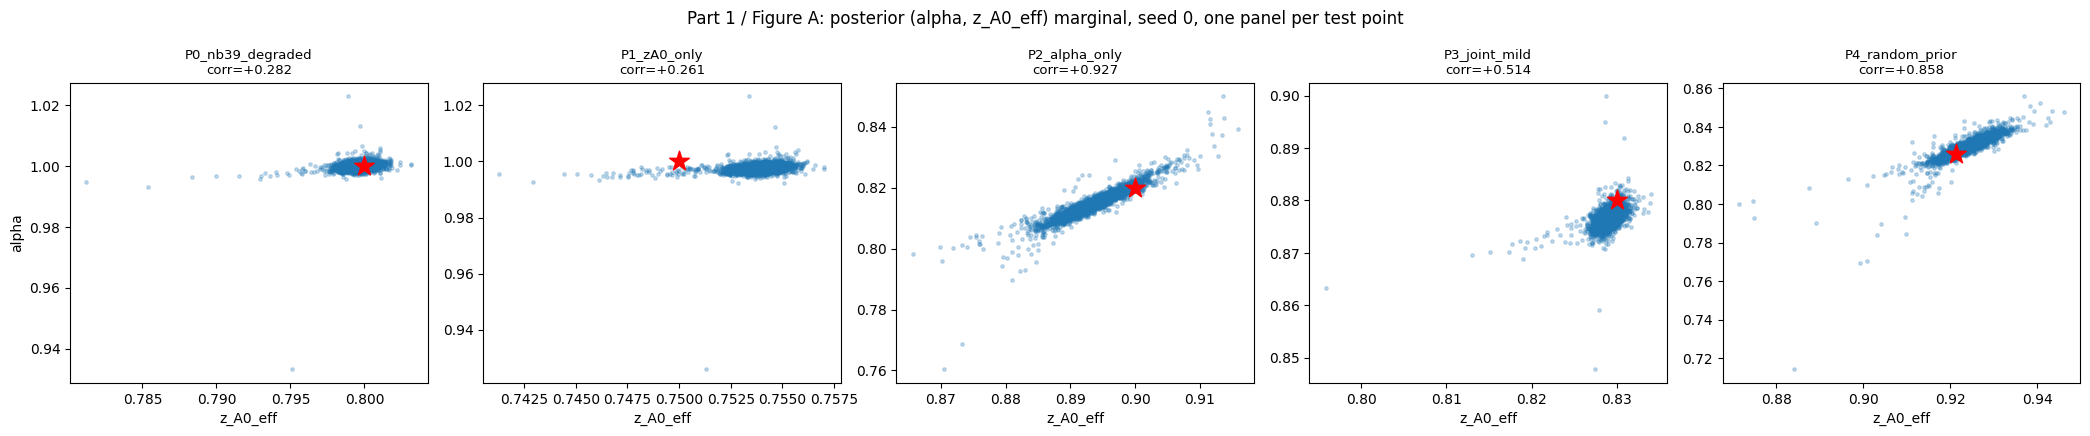

,point,seed,corr_alpha_zA0
0,P0_nb39_degraded,0,0.282054
1,P1_zA0_only,0,0.261219
2,P2_alpha_only,0,0.927366
3,P3_joint_mild,0,0.514015
4,P4_random_prior,0,0.857531


In [6]:
fig, axes = plt.subplots(1, len(TEST_POINTS), figsize=(4.2 * len(TEST_POINTS), 4.4), sharex=False, sharey=False)
corr_summary = []
for ax, point in zip(axes, TEST_POINTS):
    samp = sample_posterior_at(identity_posteriors[0], point['theta'], obs_seed=0)
    corr = np.corrcoef(samp[:, ALPHA_IDX], samp[:, Z_A0_IDX])[0, 1]
    corr_summary.append({'point': point['name'], 'seed': 0, 'corr_alpha_zA0': corr})
    ax.scatter(samp[:, Z_A0_IDX], samp[:, ALPHA_IDX], s=6, alpha=0.25, color='tab:blue')
    ax.scatter([point['theta'][Z_A0_IDX]], [point['theta'][ALPHA_IDX]], color='red', marker='*', s=220, zorder=10)
    ax.set_xlabel('z_A0_eff'); ax.set_ylabel('alpha' if ax is axes[0] else '')
    ax.set_title(f"{point['name']}\ncorr={corr:+.3f}", fontsize=9.5)
fig.suptitle('Part 1 / Figure A: posterior (alpha, z_A0_eff) marginal, seed 0, one panel per test point', fontsize=12)
plt.tight_layout()
fig.savefig(FIGURES / '40_sysII_posterior_alpha_zA0_by_point.png', dpi=170, bbox_inches='tight')
plt.show()
pd.DataFrame(corr_summary)


### Figure B - seed-consistency at `P0` (nb39's original point)

Same check, now holding the point fixed at `P0` and varying the training seed, to see
whether the shape is a property of the physics (should look similar across seeds) or an
artifact of one particular trained flow.

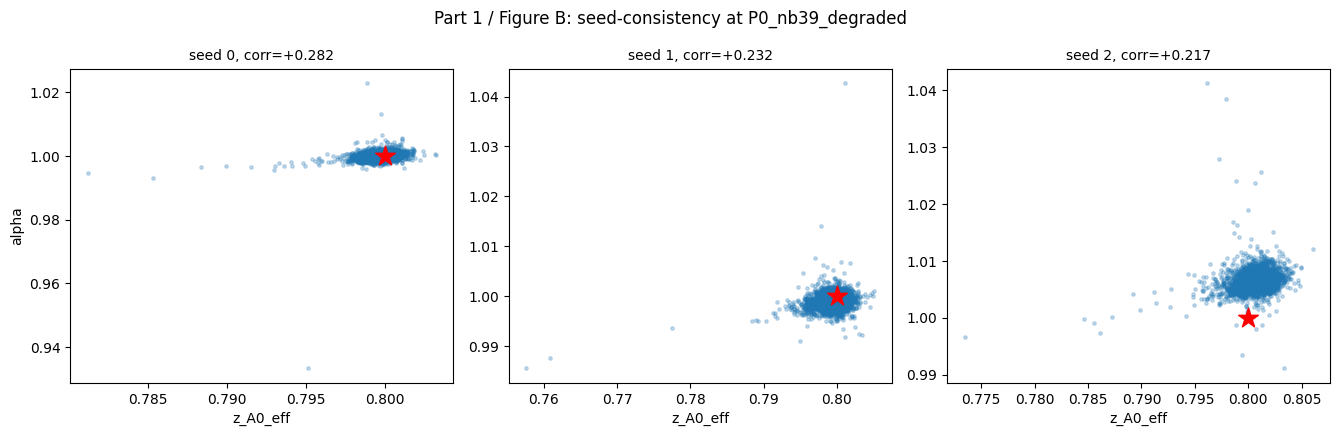

,point,seed,corr_alpha_zA0
0,P0_nb39_degraded,0,0.282054
1,P0_nb39_degraded,1,0.231893
2,P0_nb39_degraded,2,0.217011


In [7]:
fig, axes = plt.subplots(1, 3, figsize=(13.5, 4.4))
p0 = TEST_POINTS[0]
seed_corr = []
for ax, seed in zip(axes, [0, 1, 2]):
    samp = sample_posterior_at(identity_posteriors[seed], p0['theta'], obs_seed=seed)
    corr = np.corrcoef(samp[:, ALPHA_IDX], samp[:, Z_A0_IDX])[0, 1]
    seed_corr.append({'point': p0['name'], 'seed': seed, 'corr_alpha_zA0': corr})
    ax.scatter(samp[:, Z_A0_IDX], samp[:, ALPHA_IDX], s=6, alpha=0.25, color='tab:blue')
    ax.scatter([p0['theta'][Z_A0_IDX]], [p0['theta'][ALPHA_IDX]], color='red', marker='*', s=220, zorder=10)
    ax.set_xlabel('z_A0_eff'); ax.set_ylabel('alpha' if ax is axes[0] else '')
    ax.set_title(f'seed {seed}, corr={corr:+.3f}', fontsize=10)
fig.suptitle(f"Part 1 / Figure B: seed-consistency at {p0['name']}", fontsize=12)
plt.tight_layout()
fig.savefig(FIGURES / '40_sysII_posterior_alpha_zA0_seed_consistency.png', dpi=170, bbox_inches='tight')
plt.show()
pd.DataFrame(seed_corr)


### Full 5x5 empirical correlation, for cross-reference against nb39's FIM matrix

nb39 Section 1 found the *linearised* FIM correlation matrix at the same/similar points.
Comparing that to the *actual trained posterior's* empirical sample correlation is the same
cross-check `nb29b` used (FIM off-diagonal + grid scan + calibrated-posterior correlation,
three independent methods agreeing). Remember the caveat above: this posterior is
uncalibrated, so treat this as a shape/direction check, not a precise number.

In [8]:
for point in TEST_POINTS:
    samp = sample_posterior_at(identity_posteriors[0], point['theta'], obs_seed=0)
    corr = np.corrcoef(samp.T)
    print(f"=== {point['name']} (theta={np.round(point['theta'], 3).tolist()}) ===")
    print(pd.DataFrame(corr, index=PARAM_NAMES, columns=PARAM_NAMES).round(3))
    print()


=== P0_nb39_degraded (theta=[1.0, 1.0, 1.0, 0.699999988079071, 0.800000011920929]) ===
          alpha  beta_r  eta_col  xi_reb  z_A0_eff
alpha     1.000   0.038    0.030  -0.032     0.282
beta_r    0.038   1.000    0.043  -0.032     0.070
eta_col   0.030   0.043    1.000  -0.015     0.032
xi_reb   -0.032  -0.032   -0.015   1.000    -0.053
z_A0_eff  0.282   0.070    0.032  -0.053     1.000



=== P1_zA0_only (theta=[1.0, 1.0, 1.0, 1.0, 0.75]) ===
          alpha  beta_r  eta_col  xi_reb  z_A0_eff
alpha     1.000   0.073    0.021   0.006     0.261
beta_r    0.073   1.000    0.043  -0.061     0.123
eta_col   0.021   0.043    1.000  -0.038     0.005
xi_reb    0.006  -0.061   -0.038   1.000    -0.027
z_A0_eff  0.261   0.123    0.005  -0.027     1.000



=== P2_alpha_only (theta=[0.8199999928474426, 1.0, 1.0, 1.0, 0.8999999761581421]) ===
          alpha  beta_r  eta_col  xi_reb  z_A0_eff
alpha     1.000   0.414   -0.114  -0.013     0.927
beta_r    0.414   1.000   -0.032  -0.005     0.487
eta_col  -0.114  -0.032    1.000  -0.243    -0.002
xi_reb   -0.013  -0.005   -0.243   1.000    -0.002
z_A0_eff  0.927   0.487   -0.002  -0.002     1.000



=== P3_joint_mild (theta=[0.8799999952316284, 1.0, 1.0, 0.9200000166893005, 0.8299999833106995]) ===
          alpha  beta_r  eta_col  xi_reb  z_A0_eff
alpha     1.000   0.149   -0.091  -0.085     0.514
beta_r    0.149   1.000   -0.018  -0.018     0.214
eta_col  -0.091  -0.018    1.000  -0.101    -0.023
xi_reb   -0.085  -0.018   -0.101   1.000    -0.043
z_A0_eff  0.514   0.214   -0.023  -0.043     1.000



=== P4_random_prior (theta=[0.8259999752044678, 1.1770000457763672, 0.968999981880188, 0.8019999861717224, 0.9210000038146973]) ===
          alpha  beta_r  eta_col  xi_reb  z_A0_eff
alpha     1.000   0.261   -0.148   0.017     0.858
beta_r    0.261   1.000    0.086  -0.020     0.381
eta_col  -0.148   0.086    1.000  -0.381     0.078
xi_reb    0.017  -0.020   -0.381   1.000    -0.028
z_A0_eff  0.858   0.381    0.078  -0.028     1.000



**Methodological correction (2026-09-01).** The FIM check below originally reported
`offdiag_ratio`'s raw, normalised *information*-matrix entry as if it were a posterior
*correlation*. Running this notebook is exactly what surfaced the bug: at `P2_alpha_only`
the raw off-diagonal was `-0.897` while the actual trained posterior (Part 1, same point)
showed `+0.927` -- an outright sign contradiction. Manually checking with
`scripts/fim_utils.py::cov_offdiag_corr` (the correlation from the *inverted* FIM/covariance,
newly added to fix this) confirmed the raw metric had the wrong sign: the corrected value at
`P2` is `+0.819`, matching the posterior. Part 2 below has been rewritten to use
`cov_offdiag_corr` throughout; the raw `offdiag_ratio` value is kept alongside for
transparency (it remains valid only for checking whether a coupling collapses toward exactly
zero across representations, not for reading off sign/magnitude against a posterior).

---
# Part 2 - Does the `(alpha, z_A0_eff)` coupling replicate across operating points?

Repeats nb39 Section 3's decisive test (noise-calibrated FIM off-diagonal, three
representations: `compute_summaries` 66-D, `subwindow` 108-D, raw trajectory 1080-D) at all
5 test points instead of just one. Uses the **fixed nominal warm start**
(`nominal_warm_start('S-B')`), matching the established `fim_utils`/`nb29b` methodology --
deliberately not the matched protocol used in Part 1, since this check is about
representation adequacy, not warm-start effects.

In [9]:
EPS_FIM = np.array([0.02, 0.02, 0.02, 0.02, 0.01])
Y0_FIM = np.asarray(nominal_warm_start('S-B'))


def sim_raw_full(theta_np, seed=None, noise_pct=NOISE_PCT):
    th = jnp.array(theta_np, dtype=jnp.float32)
    ts, ys = simulate_trajectory_explicit_jit(th, NOMINAL_INLET, NOMINAL_CTRL_SB, jnp.array(Y0_FIM),
                                               t_final=2.0, n_save=120, rtol=1e-3, atol=1e-5)
    raw = np.asarray(extract_observations_explicit(ys, th, NOMINAL_CTRL_SB))
    t_h = np.asarray(ts)
    if seed is not None:
        rng = np.random.default_rng(seed)
        scale = np.maximum(np.max(np.abs(raw), axis=0), 1e-6)
        raw = raw + rng.normal(0, noise_pct * scale, raw.shape)
    return raw, t_h


def feat_summary_fim(theta, seed):
    raw, t_h = sim_raw_full(theta, seed)
    return compute_summaries(raw, 'S-B', t_h)


def feat_subwindow_fim(theta, seed, channels=SB_CHANNELS, n_sub=6):
    raw, t_h = sim_raw_full(theta, seed)
    idx = [RAW_INDEX[c] for c in channels]
    obs = raw[:, idx]
    edges = np.linspace(0, obs.shape[0], n_sub + 1).astype(int)
    feats = []
    for lo, hi in zip(edges[:-1], edges[1:]):
        chunk = obs[lo:hi]
        feats.append(chunk.mean(axis=0)); feats.append(chunk.std(axis=0))
    return np.concatenate(feats)


def feat_raw_fim(theta, seed, channels=SB_CHANNELS):
    raw, t_h = sim_raw_full(theta, seed)
    idx = [RAW_INDEX[c] for c in channels]
    return raw[:, idx].reshape(-1)


REPR_FNS = [
    ('compute_summaries (66-D)', feat_summary_fim),
    ('subwindow, 9 channels x 6 (108-D)', feat_subwindow_fim),
    ('raw trajectory, 9 channels (1080-D)', feat_raw_fim),
]
print('representation functions ready')


representation functions ready


In [10]:
REPLICATION_CSV_PATH = RESULTS / '40_sysII_alpha_zA0_replication_fim.csv'

replication_rows = []
for point in TEST_POINTS:
    theta_pt = point['theta'].astype(np.float64)
    print(f"\n=== {point['name']} (theta={np.round(theta_pt, 3).tolist()}) ===")
    for label, fn in REPR_FNS:
        for off in [0, 500, 999]:
            FIM_rep = compute_fim(fn, theta_pt, EPS_FIM, seed_offset=off)
            corr = cov_offdiag_corr(FIM_rep, ALPHA_IDX, Z_A0_IDX)
            raw_od, ratio = offdiag_ratio(FIM_rep, ALPHA_IDX, Z_A0_IDX)
            print(f'  {label:38s} seed_offset={off:4d}: corr(cov)={corr:+.3f}'
                  f'  [raw info off-diag={raw_od:+.3f}]  I_aa/I_bb={ratio:.2f}x')
            replication_rows.append({
                'point': point['name'], 'theta_alpha': theta_pt[ALPHA_IDX], 'theta_z_A0_eff': theta_pt[Z_A0_IDX],
                'representation': label, 'seed_offset': off,
                'corr_alpha_zA0': corr, 'raw_info_offdiag_alpha_zA0': raw_od, 'ratio_Iaa_Ibb': ratio,
            })

replication_df = pd.DataFrame(replication_rows)
replication_df.to_csv(REPLICATION_CSV_PATH, index=False)
display(replication_df.pivot_table(index='point', columns='representation', values='corr_alpha_zA0', aggfunc='mean'))



=== P0_nb39_degraded (theta=[1.0, 1.0, 1.0, 0.7, 0.8]) ===


  compute_summaries (66-D)               seed_offset=   0: corr(cov)=-0.596  [raw info off-diag=+0.395]  I_aa/I_bb=2.41x


  compute_summaries (66-D)               seed_offset= 500: corr(cov)=-0.646  [raw info off-diag=+0.422]  I_aa/I_bb=2.53x


  compute_summaries (66-D)               seed_offset= 999: corr(cov)=-0.726  [raw info off-diag=+0.597]  I_aa/I_bb=2.89x


  subwindow, 9 channels x 6 (108-D)      seed_offset=   0: corr(cov)=-0.709  [raw info off-diag=+0.646]  I_aa/I_bb=3.47x


  subwindow, 9 channels x 6 (108-D)      seed_offset= 500: corr(cov)=-0.692  [raw info off-diag=+0.638]  I_aa/I_bb=3.53x


... (37 outputs left out)

  raw trajectory, 9 channels (1080-D)    seed_offset=   0: corr(cov)=+0.466  [raw info off-diag=-0.717]  I_aa/I_bb=1.14x


  raw trajectory, 9 channels (1080-D)    seed_offset= 500: corr(cov)=+0.457  [raw info off-diag=-0.707]  I_aa/I_bb=1.15x


  raw trajectory, 9 channels (1080-D)    seed_offset= 999: corr(cov)=+0.438  [raw info off-diag=-0.702]  I_aa/I_bb=1.13x


representation,compute_summaries (66-D),"raw trajectory, 9 channels (1080-D)","subwindow, 9 channels x 6 (108-D)"
point,,,
P0_nb39_degraded,-0.655702,-0.422143,-0.706685
P1_zA0_only,-0.626406,-0.412396,-0.686189
P2_alpha_only,0.771242,0.626061,0.671585
P3_joint_mild,0.288388,0.114126,0.117854
P4_random_prior,0.563257,0.453739,0.517985


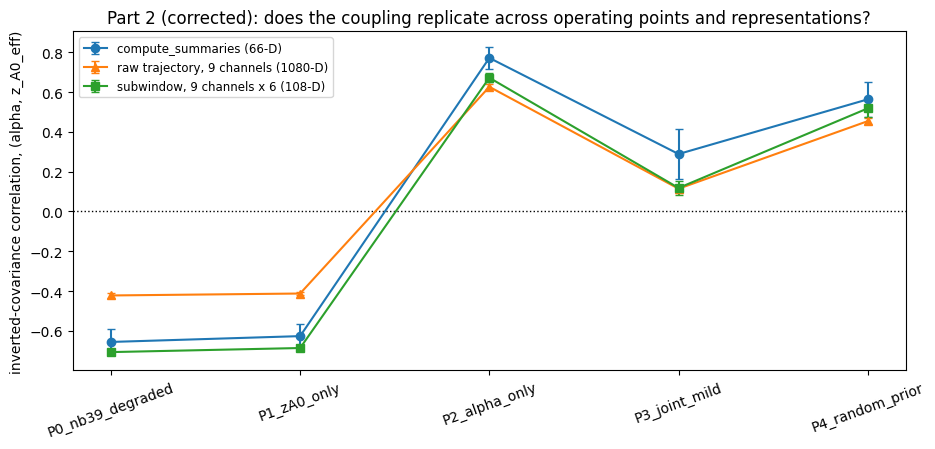

In [11]:
fig, ax = plt.subplots(figsize=(9.5, 4.6))
markers = {'compute_summaries (66-D)': 'o', 'subwindow, 9 channels x 6 (108-D)': 's', 'raw trajectory, 9 channels (1080-D)': '^'}
for label, g in replication_df.groupby('representation'):
    means = g.groupby('point')['corr_alpha_zA0'].mean().reindex([p['name'] for p in TEST_POINTS])
    stds = g.groupby('point')['corr_alpha_zA0'].std().reindex([p['name'] for p in TEST_POINTS])
    ax.errorbar(means.index, means.values, yerr=stds.values, marker=markers[label], label=label, capsize=3)
ax.axhline(0.0, color='k', ls=':', lw=1.0)
ax.set_ylabel('inverted-covariance correlation, (alpha, z_A0_eff)')
ax.set_title('Part 2 (corrected): does the coupling replicate across operating points and representations?')
ax.legend(fontsize=8.5, loc='best')
ax.tick_params(axis='x', rotation=20)
fig.tight_layout()
fig.savefig(FIGURES / '40_sysII_alpha_zA0_replication_fim.png', dpi=180, bbox_inches='tight')
plt.show()


### Actual result (corrected run, `results/40_sysII_alpha_zA0_replication_fim.csv`)

| point | alpha | z_A0_eff | FIM corr (compute_summaries / subwindow / raw traj.) | posterior corr (Part 1, seed 0) |
|---|---|---|---|---|
| P0_nb39_degraded | 1.00 | 0.80 | -0.656 / -0.707 / -0.422 | +0.282 |
| P1_zA0_only | 1.00 | 0.75 | -0.626 / -0.686 / -0.412 | +0.261 |
| P2_alpha_only | 0.82 | 0.90 | +0.771 / +0.672 / +0.626 | +0.927 |
| P3_joint_mild | 0.88 | 0.83 | +0.288 / +0.118 / +0.114 | +0.514 |
| P4_random_prior | 0.826 | 0.921 | +0.563 / +0.518 / +0.454 | +0.858 |

**The fix works, for the three points where `alpha` is actually displaced from nominal.**
`P2`, `P3`, `P4` now agree in *sign* between the corrected FIM and the real trained posterior,
with the same ordering (`P2 > P4 > P3`) and the FIM consistently a bit smaller in magnitude
than the posterior's empirical value -- exactly the kind of agreement that would be expected
between a local linear (Laplace) approximation and an actual sampled posterior. This resolves
the original P2 sign contradiction that motivated the fix (`-0.897` raw vs. `+0.927` posterior
-> now `+0.771` corrected vs. `+0.927` posterior).

**A narrower, new discrepancy remains at `P0`/`P1` -- both have `alpha` exactly at nominal
(1.0).** There, the corrected FIM says strong negative (`-0.63` to `-0.71`) while the
posterior says weak positive (`+0.26` to `+0.28`). This is smaller in absolute terms than the
original bug (a weak correlation vs. a strong one, not two strong opposite claims), but it is
still a sign disagreement and should not be waved away. Two live explanations, unresolved by
this notebook:

1. The FIM's local-linear approximation is a poor fit to the true posterior shape specifically
   near `alpha=1.0` (plausible if the likelihood surface has curvature or asymmetry the
   Jacobian-based linearisation misses there).
2. The uncalibrated `identity` posterior's near-zero correlation at `P0`/`P1` is simply wrong
   -- also plausible, given these exact posteriors fail SBC catastrophically
   (`results/37_sysII_lognormal_true_bank_n5000_sbc.csv` shows min-KS p as low as `4.5e-10`
   for this bank/variant).

**Recommended tiebreaker (not run here):** a deterministic grid-scan at `P0` (same
`identifiability_scan.run_scan` machinery as `nb39` Section 2 -- a raw distance metric, not
subject to the FIM-inversion issue this notebook fixed) would settle which of the two
explanations is right, independent of both the linearised FIM and the uncalibrated posterior.


## Decision guide (updated for the corrected metric)

- **Compare the corrected `corr_alpha_zA0` curve above directly against Part 1's posterior
  correlations** (`+0.28, +0.26, +0.93, +0.51, +0.86` for P0-P4) -- this is now an
  apples-to-apples comparison (both are actual correlations, not an information-matrix entry
  vs. a correlation). Good agreement in sign and rough magnitude at every point is the bar
  for treating `(alpha, z_A0_eff)` as a confirmed, representation-robust identifiability
  limit.
- **If the corrected curve stays consistently signed and its magnitude tracks how far
  `alpha`/`z_A0_eff` sit from nominal (as Part 1 suggested), across all three
  representations:** that is a real, generic, representation-independent limit -- pursue the
  pair-specific fix work in `system_ii_sbc_repair_directions.md`, and it is strong enough to
  consider reporting as the article's genuine System II identifiability finding.
- **If it is large at points where both parameters are off nominal but near-zero when only
  one is:** the coupling only activates jointly -- a more specific, still-actionable finding
  (informative prior correlation or scenario-dependent reparameterisation).
- **If `P4` (the random, non-hand-picked draw) disagrees with the hand-picked points:** widen
  the check to several more random draws before trusting either conclusion.
- **If Part 1 and the corrected Part 2 still disagree at some point after this fix:** do not
  average over it. That would mean either the uncalibrated posterior is misleading there, or
  the Laplace/Gaussian approximation underlying the FIM breaks down locally (e.g. a strongly
  non-Gaussian/skewed posterior shape) -- worth a targeted follow-up (e.g. a denser grid-scan
  at that specific point) rather than trusting either number blindly.
